# Semi-endogenous time-to-build: full re-optimization with a binding `delta`

An alternative solution of the model in `semi_endo_A.ipynb`. The calibration stage
(`c`, `N`, `tau`) and the staggering matrix are kept **identical** so the results are
directly comparable; only the way shocked firms respond is solved differently.

**What `semi_endo_A.ipynb` does.** Wherever the staggering matrix marks a firm as hit,
it overwrites that entry with `max(tprod(tau+1), tprod(tau-1))` — a one-step search that
(i) never considers *staying* on the pre-shock schedule and (ii) drops the shock factor
entirely, so a re-timing firm ends up strictly more productive than an unshocked one.
Its `compute_semi_endo_response(..., delta, ...)` never uses `delta` and is never called.

**What this notebook does instead.**

1. *Full re-optimization.* Each firm chooses its integer lag by maximizing over the whole
   grid `t = 0..T`, not just `tau ± 1`, and the stay-put option is priced with the shock:

   $$V_i(t) \;=\; \begin{cases}\text{shock}\cdot(\beta c)^{t}(t+N_i) & t = \tau_i^{\text{old}}\\ (\beta c)^{t}(t+N_i) & t \neq \tau_i^{\text{old}}\end{cases}
   \qquad \tau_i^{\text{new}} = \arg\max_t V_i(t)$$

   The shock is therefore an *escapable* cost: a firm avoids it by moving off its
   pre-shock schedule, but pays for leaving its unconstrained optimum.

2. *Binding `delta`.* A fraction `delta` of firms is frozen and must eat the full shock;
   the remaining `1 - delta` re-optimize as above. Sweeping `delta` traces a continuous
   family between the two cases the original notebook plots as separate branches.
   `delta = 1` reproduces its exogenous path exactly (asserted below).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## Parameters

The productivity shock is a named parameter here rather than a literal buried inside the
matrix generator. `SHOCK = 0.97` is the 3% decline used in `semi_endo_A.ipynb`.

In [2]:
sigma = 5
gamma = 1
eta   = 2
power = (1 + eta) / (-gamma - eta)

beta  = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
W = 1

SHOCK  = 0.97                          # 3% productivity decline
DELTAS = [0.0, 0.25, 0.5, 0.75, 1.0]   # fraction of firms frozen at the old tau
SEED   = 0                             # which firms are frozen (nested across DELTAS)

## Calibration

Unchanged from `semi_endo_A.ipynb`: pick `c` so the mean gap between the time-to-produce
implied by `beta` and by `beta1` is one period.

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_grid   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(len(c_grid))

for i, c_try in enumerate(c_grid):
    N_try = -(data_tau) - 1 / np.log(beta * c_try)
    t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
    t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)
    tau_diff[i] = np.mean(np.abs(t1 - t2))

c = np.min(c_grid[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])
print(f'calibrated c = {c:.6f}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_30954/3474285434.py:8: RuntimeWarning: divide by zero encountered in log
  N_try = -(data_tau) - 1 / np.log(beta * c_try)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_30954/3474285434.py:9: RuntimeWarning: divide by zero encountered in log
  t1 = np.clip(-1 / np.log(beta  * c_try) - N_try, 0, None)
/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_30954/3474285434.py:10: RuntimeWarning: divide by zero encountered in log
  t2 = np.clip(-1 / np.log(beta1 * c_try) - N_try, 0, None)


calibrated c = 0.901802


In [4]:
N = np.asarray(-data_tau - 1 / np.log(beta * c))

tau = np.clip(-1 / np.log(beta * c) - N, 0, None)
tau_floor, tau_ceil = np.floor(tau), np.ceil(tau)
tprod_ceil  = (beta * c) ** tau_ceil  * (tau_ceil  + N)
tprod_floor = (beta * c) ** tau_floor * (tau_floor + N)
tau = np.where(tprod_ceil > tprod_floor, tau_ceil,
      np.where(tprod_ceil < tprod_floor, tau_floor, tau))
tau = np.clip(tau, 0, None).astype(int)

# same reversal the original applies before building the matrix
tau_old = tau[::-1].copy()
N_v     = N[::-1].copy()
n_firms = len(tau_old)

print(f'{n_firms} firms, tau in [{tau_old.min()}, {tau_old.max()}]')

269 firms, tau in [0, 13]


## Full re-optimization over the integer grid

`V[i, t]` is firm `i`'s payoff from choosing lag `t`. Before checking anything else, the
unshocked grid argmax must reproduce the floor/ceil rounding the original notebook uses —
otherwise the two solutions would differ for reasons unrelated to the shock response.

In [5]:
T_GRID = np.arange(0, 60)

def tprod(t, N_x):
    '''Firm productivity from choosing production lag t.'''
    return (beta * c) ** t * (t + N_x)

V = tprod(T_GRID[None, :], N_v[:, None])

assert np.array_equal(T_GRID[V.argmax(axis=1)], tau_old), \
    'grid argmax disagrees with the floor/ceil rounding'
print('grid argmax reproduces the floor/ceil tau for all firms')

# single-peakedness: at most one sign change in the first difference
sign_changes = [np.sum(np.diff(np.sign(np.diff(V[i]))) != 0) for i in range(n_firms)]
print(f'max sign changes in dV/dt: {max(sign_changes)}  (1 => single peak)')

grid argmax reproduces the floor/ceil tau for all firms
max sign changes in dV/dt: 1  (1 => single peak)


In [6]:
# staying on the pre-shock schedule is the only choice that incurs the shock
V_shocked = V.copy()
V_shocked[np.arange(n_firms), tau_old] *= SHOCK

tau_new    = T_GRID[V_shocked.argmax(axis=1)]
val_free   = V_shocked.max(axis=1)                       # firm re-optimizes
val_frozen = SHOCK * V[np.arange(n_firms), tau_old]      # firm stuck at tau_old

n_retime = int((tau_new != tau_old).sum())
print(f're-timing firms: {n_retime} / {n_firms}')
print('lag changes:', dict(zip(*np.unique(tau_new - tau_old, return_counts=True))))

re-timing firms: 269 / 269
lag changes: {-1: 132, 1: 137}


Because the objective is single-peaked in `t`, the full-grid search collapses to a
comparison of `tau_old ± 1` — so the original's `±1` neighbourhood was not the binding
restriction. What changes the answer is pricing the stay-put option at `SHOCK * tprod(tau_old)`
instead of ignoring it.

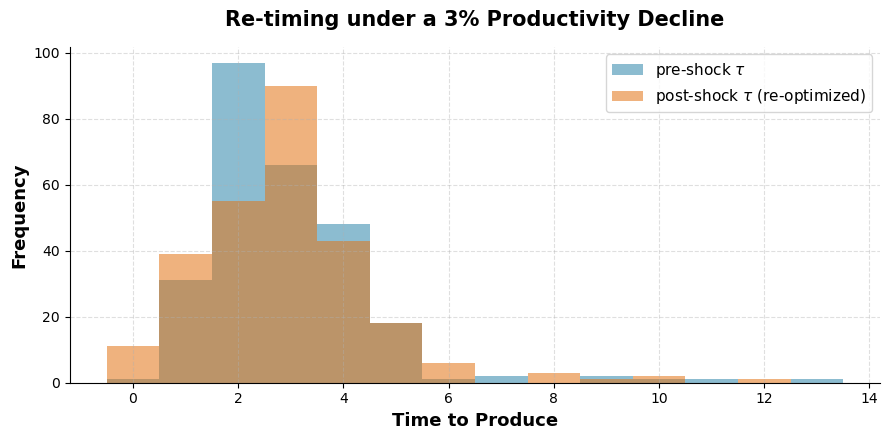

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(-0.5, tau_old.max() + 1.5)
ax.hist(tau_old, bins=bins, alpha=0.55, label='pre-shock $\\tau$', color='#2E86AB')
ax.hist(tau_new, bins=bins, alpha=0.55, label='post-shock $\\tau$ (re-optimized)', color='#E27414')
ax.set_xlabel('Time to Produce', fontsize=13, weight='bold')
ax.set_ylabel('Frequency', fontsize=13, weight='bold')
ax.set_title(f'Re-timing under a {100*(1-SHOCK):.0f}% Productivity Decline',
             fontsize=15, weight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../semi_endo_reopt_tau.png', dpi=150)
plt.show()

## Staggering structure

Same construction as `generate_pattern_array_with_extra_rows`, but returning a boolean
mask of *which* (period, firm) cells are hit rather than a matrix of shock values. The
mask is what lets each hit cell take a firm-specific value below. The assertion confirms
it is the same object the original builds.

In [8]:
def shock_mask(t):
    '''Boolean (period x firm) mask of shocked cells.

    Identical placement to generate_pattern_array_with_extra_rows in semi_endo_A.ipynb;
    only the payload differs (mask instead of hardcoded shock value).
    '''
    t = np.asarray(t)
    n = len(t) + int(t.min())
    m = int(t.max()) + int(t.min())
    missing_count = len(set(range(int(t.max()) + 1)) - set(t))

    M = np.zeros((m + 2, n + missing_count), dtype=bool)
    count = 0
    for i in range(1, m + 2):
        k = int((t == i - 1).sum())
        for j in range(k):
            M[i, n - i - j - count] = True
        if k > 1:
            count += k - 1

    M = np.vstack([M, np.zeros(n + missing_count, dtype=bool)])
    return M[:, 0:n - int(t.min())]


def generate_pattern_array_with_extra_rows(tau, shock=SHOCK):
    '''Original generator, with the shock literal promoted to an argument.'''
    return np.where(shock_mask(tau), shock, 1.0)


M = shock_mask(tau_old)
assert np.array_equal(np.where(M, SHOCK, 1.0),
                      generate_pattern_array_with_extra_rows(tau_old))
print(f'mask {M.shape}: {M.sum()} shocked cells over {M.shape[0]} periods')

mask (16, 269): 268 shocked cells over 16 periods


## Solving for a given `delta`

Frozen firms are drawn once from a seeded permutation and the first `delta * n` are held
fixed, so the sets are **nested** as `delta` rises — the sweep is then a clean comparative
static rather than a set of independent draws.

In [9]:
tprod_old  = tprod(tau_old, N_v)
freeze_order = np.random.default_rng(SEED).permutation(n_firms)


def solve(delta):
    '''Return consumption and inflation paths when a fraction delta of firms is frozen.'''
    frozen = np.zeros(n_firms, dtype=bool)
    frozen[freeze_order[:int(round(delta * n_firms))]] = True

    # effective productivity: unshocked firms keep tprod_old, hit cells take the
    # frozen or re-optimized value depending on the firm
    eff = np.tile(tprod_old, (M.shape[0], 1))
    hit_value = np.where(frozen, val_frozen, val_free)
    eff[M] = np.broadcast_to(hit_value, M.shape)[M]

    P0 = (np.sum(1 / eff ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
    C  = P0 ** power / P0[0] ** power - 1

    C_pad = np.zeros(len(C) + 1)
    C_pad[1:] = C
    pi = -(C_pad[1:] - C_pad[:-1])
    return C, pi, frozen

In [10]:
# delta = 1 (nobody re-optimizes) must reproduce the exogenous path of semi_endo_A.ipynb
A_orig  = generate_pattern_array_with_extra_rows(tau_old)
P0_orig = (np.sum(1 / (A_orig * tprod_old) ** (1 - sigma), axis=1)) ** (1 / (1 - sigma))
C_orig  = P0_orig ** power / P0_orig[0] ** power - 1

C_check, _, _ = solve(1.0)
assert np.allclose(C_check, C_orig), 'delta=1 does not reproduce the exogenous benchmark'
print(f'delta=1 reproduces the original exogenous path (max abs diff '
      f'{np.abs(C_check - C_orig).max():.2e})')

delta=1 reproduces the original exogenous path (max abs diff 0.00e+00)


## Impulse responses across `delta`

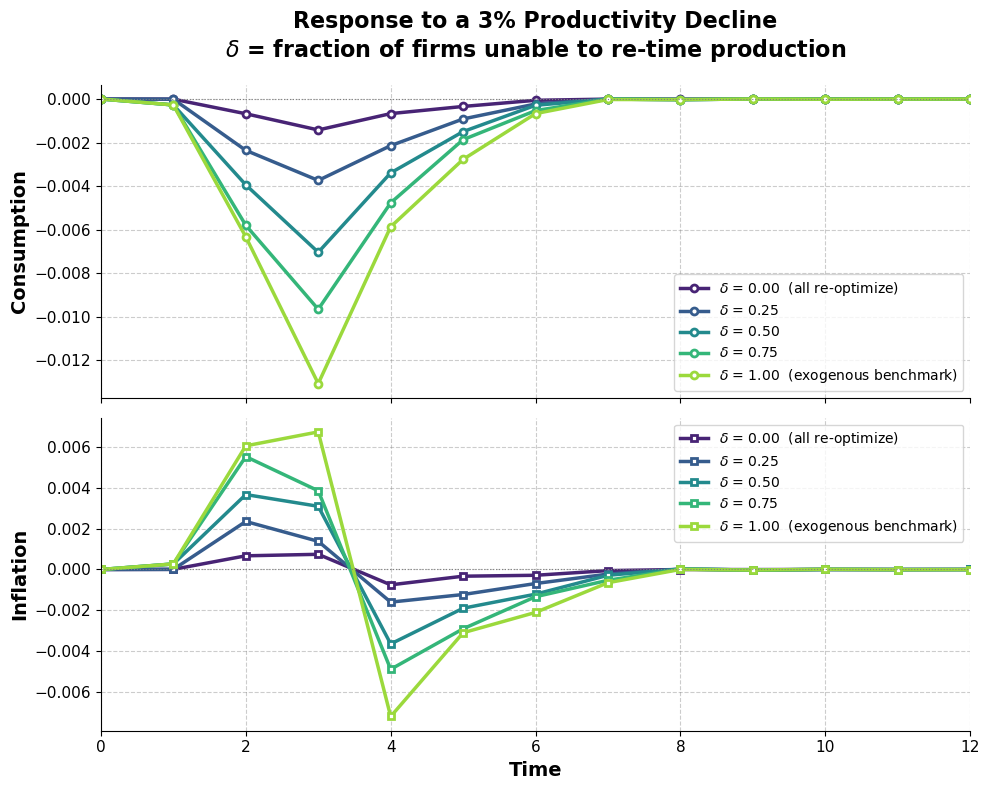

In [11]:
results = {d: solve(d) for d in DELTAS}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(DELTAS)))

for (d, (C, pi, _)), col in zip(results.items(), colors):
    label = f'$\\delta$ = {d:.2f}'
    if d == 0.0:
        label += '  (all re-optimize)'
    if d == 1.0:
        label += '  (exogenous benchmark)'
    ax1.plot(C,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=label)
    ax2.plot(pi, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=label)

ax1.set_title(f'Response to a {100*(1-SHOCK):.0f}% Productivity Decline\n'
              f'$\\delta$ = fraction of firms unable to re-time production',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Consumption', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../semi_endo_reopt_delta.png', dpi=150)
plt.show()

In [12]:
print(f'{"delta":>7} {"C trough":>11} {"pi peak":>11} {"frozen":>8}')
for d, (C, pi, frozen) in results.items():
    print(f'{d:>7.2f} {C.min():>11.5f} {pi.max():>11.5f} {frozen.sum():>8d}')

  delta    C trough     pi peak   frozen
   0.00    -0.00142     0.00074        0
   0.25    -0.00374     0.00235       67
   0.50    -0.00704     0.00367      134
   0.75    -0.00966     0.00553      202
   1.00    -0.01307     0.00674      269


## Extensive margin: when does re-timing actually happen?

A firm re-times when the shock exceeds the productivity it gives up by moving one step
off its optimum. That loss is tiny for this calibration, so the extensive margin
saturates well below the 3% shock — which is why `delta`, not the shock size, is the
knob that moves the responses above.

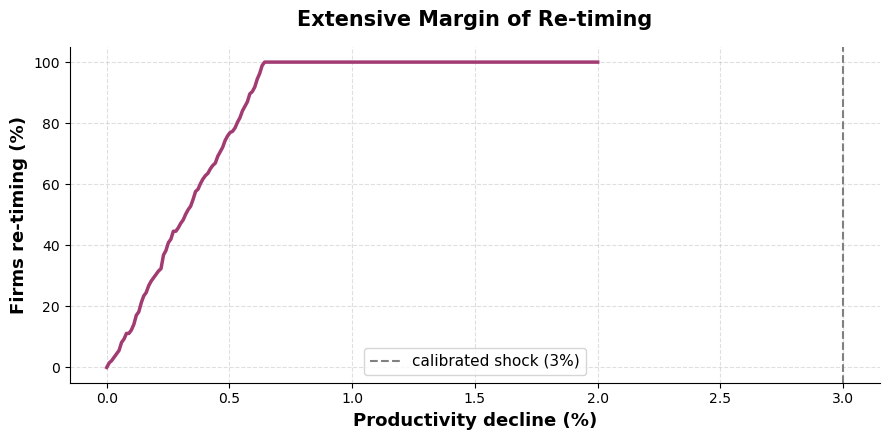

one-step loss: min 0.00001  median 0.00317  max 0.00637


In [13]:
best   = V[np.arange(n_firms), tau_old]
second = V.copy()
second[np.arange(n_firms), tau_old] = -np.inf
loss = 1 - second.max(axis=1) / best     # relative cost of moving one step

shock_grid  = np.linspace(0.0, 0.02, 200)
retime_share = [(s > loss).mean() for s in shock_grid]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(100 * shock_grid, 100 * np.array(retime_share), lw=2.5, color='#A23B72')
ax.axvline(100 * (1 - SHOCK), color='gray', linestyle='--', lw=1.5,
           label=f'calibrated shock ({100*(1-SHOCK):.0f}%)')
ax.set_xlabel('Productivity decline (%)', fontsize=13, weight='bold')
ax.set_ylabel('Firms re-timing (%)', fontsize=13, weight='bold')
ax.set_title('Extensive Margin of Re-timing', fontsize=15, weight='bold', pad=15)
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('../semi_endo_reopt_extensive.png', dpi=150)
plt.show()

print(f'one-step loss: min {loss.min():.5f}  median {np.median(loss):.5f}  max {loss.max():.5f}')

## Summary

- The full-grid argmax reproduces the floor/ceil rounding exactly, and the payoff is
  single-peaked in the lag, so searching the whole grid gives the same answer as `tau ± 1`.
  The original's neighbourhood restriction was harmless; omitting the stay-put option was not.
- With the stay-put option priced at `SHOCK * tprod(tau_old)`, every firm re-times at a 3%
  shock — the cost of moving one step off the optimum is at most ~0.6% of productivity here,
  so the extensive margin is already saturated by a ~1% shock.
- `delta` now binds. The consumption trough runs monotonically from roughly one tenth of the
  exogenous response at `delta = 0` to the exogenous benchmark at `delta = 1`, so the share
  of firms that cannot re-time — not the size of the shock — is what governs the amplitude.